In [1]:
%matplotlib inline

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import stft, resample_poly
from ipywidgets import VBox, HBox, FloatSlider, Output, Label, Dropdown, FloatLogSlider
from IPython.display import display, clear_output, Audio
import sys
import PathGeneration as pg
from Interpolation import SplineTrajectory3D

build_dir = "cppSimulation/build"
if build_dir not in sys.path:
    sys.path.insert(0, build_dir)

import propagationmod

In [2]:
def extend_noise(x, target_samples):
    if len(x) < target_samples: 
        X = np.fft.rfft(x)
        X *= np.exp(1j*np.random.rand(len(X))*2*np.pi)
        x = np.tile(np.fft.irfft(X), (target_samples-1)//len(x)+1)
    return x[:target_samples]

def extend_audio(x, target_samples):
    if len(x) >= target_samples:
        return x[: target_samples]
    fade = 2**11
    n = len(x)
    window = np.minimum(np.minimum(np.arange(n)/fade, n/fade-np.arange(n)/fade), 1)
    grain = x * (0.5 - 0.5 * np.cos(np.pi*window))
    y = np.zeros(((target_samples-1)//n+2)*n + 4 * fade)
    for i in range(0, len(y)-n-1, n-fade):
        y[i:i+n] += grain
    return y[fade:fade+target_samples]

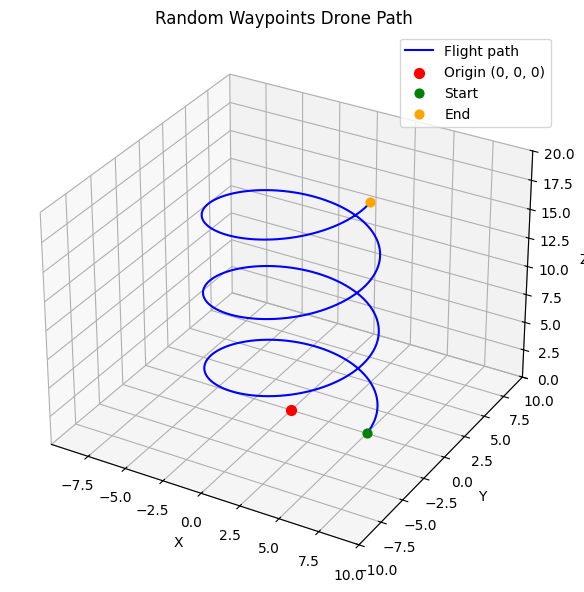

In [4]:
def plot_path_3d(points, ax, title="Drone Flight Path"):
    """
    Plot a 3D flight path and a reference point at the origin.
    points: numpy array of shape (3, N)
    t: numpy array of shape (N,)
    """
    x, y, z = points

    # Plot the path
    ax.plot(x, y, z, label='Flight path', color='blue')

    # Plot the reference point at origin
    ax.scatter(0, 0, 0, color='red', s=50, label='Origin (0, 0, 0)')

    # Optionally, show start/end points
    ax.scatter(x[0], y[0], z[0], color='green', s=40, label='Start')
    ax.scatter(x[-1], y[-1], z[-1], color='orange', s=40, label='End')

    ax.set_title(title)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

    ax.legend()
    ax.grid(True)

    # Equal aspect ratio for all axes (approximate)
    max_range = np.array([x.max() - x.min(),
                          y.max() - y.min(),
                          z.max() - z.min()]).max() / 2.0
    mid_x = (x.max() + x.min()) * 0.5
    mid_y = (y.max() + y.min()) * 0.5
    mid_z = (z.max() + z.min()) * 0.5
    ax.set_xlim(mid_x - max_range, mid_x + max_range)
    ax.set_ylim(mid_y - max_range, mid_y + max_range)
    ax.set_zlim(mid_z - max_range, mid_z + max_range)


points, t = pg.helix_climb()
interp = SplineTrajectory3D(t, points)
t = np.linspace(0, np.max(t), 1000)
pos, vel = interp.get(t)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
plot_path_3d(points, ax, title="Random Waypoints Drone Path")
plt.tight_layout()
plt.show()

In [ ]:
drone_audio_path = "../samples/mavic4_1s.wav"
channel = 0

data, sr = sf.read(drone_audio_path, always_2d=True)
if data.size == 0:
    raise RuntimeError("Empty or unsupported audio file.")

total_duration = len(data) / sr

x_full = data[:, 0]

display(Audio(x_full, rate=sr))
display(Audio(extend_audio(x_full, 10*sr), rate=sr))